In [2]:
import pandas as pd

In [3]:
demand_data = pd.read_csv('/content/duck_curve_demo_15min.csv')
demand_data.head()

,timestamp,plant_4135001_ac_power_kw,plant_4136001_ac_power_kw,total_solar_generation_kw,system_demand_synthetic_kw,illustrative_net_load_kw,generation_interpolated
0,2020-05-15 00:00:00,0.0,0.0,0.0,83.798,83.798,False
1,2020-05-15 00:15:00,0.0,0.0,0.0,83.798,83.798,False
2,2020-05-15 00:30:00,0.0,0.0,0.0,83.798,83.798,False
3,2020-05-15 00:45:00,0.0,0.0,0.0,83.799,83.799,False
4,2020-05-15 01:00:00,0.0,0.0,0.0,83.800,83.800,False


In [4]:
demand_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3264 entries, 0 to 3263
Data columns (total 7 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   timestamp                   3264 non-null   object 
 1   plant_4135001_ac_power_kw   3264 non-null   float64
 2   plant_4136001_ac_power_kw   3264 non-null   float64
 3   total_solar_generation_kw   3264 non-null   float64
 4   system_demand_synthetic_kw  3264 non-null   float64
 5   illustrative_net_load_kw    3264 non-null   float64
 6   generation_interpolated     3264 non-null   bool   
dtypes: bool(1), float64(5), object(1)
memory usage: 156.3+ KB


In [5]:
demand_data.columns

Index(['timestamp', 'plant_4135001_ac_power_kw', 'plant_4136001_ac_power_kw',
       'total_solar_generation_kw', 'system_demand_synthetic_kw',
       'illustrative_net_load_kw', 'generation_interpolated'],
      dtype='object')

In [6]:
demand_data.isnull().sum()

,0
timestamp,0
plant_4135001_ac_power_kw,0
plant_4136001_ac_power_kw,0
total_solar_generation_kw,0
system_demand_synthetic_kw,0
illustrative_net_load_kw,0
generation_interpolated,0


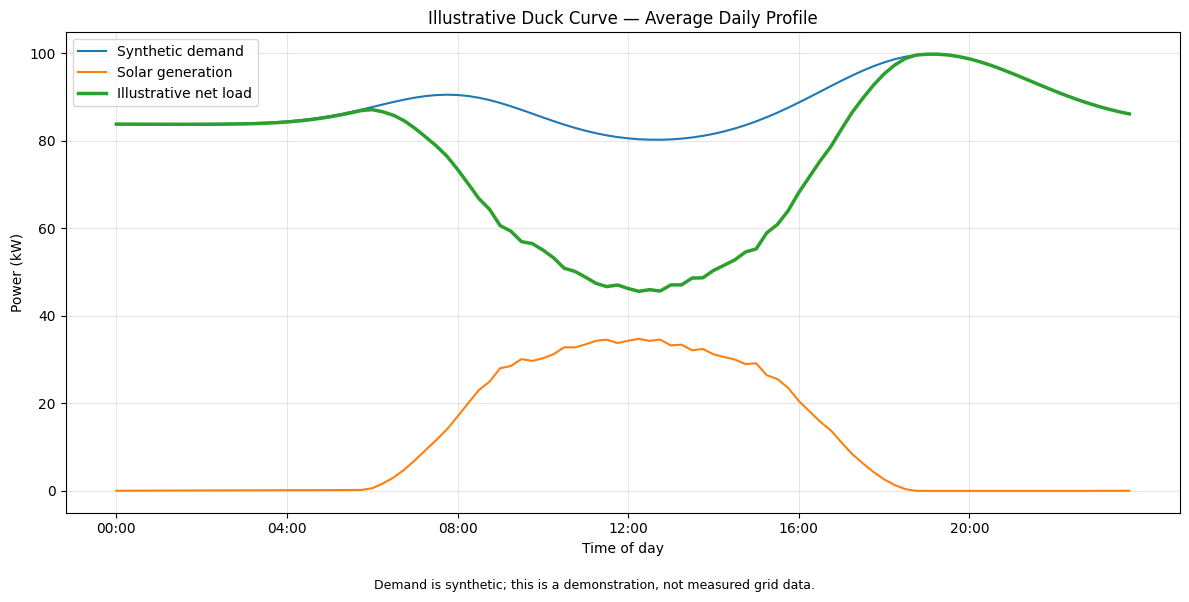

In [10]:
import io
import pandas as pd
import matplotlib.pyplot as plt

# Convert timestamp column to datetime so we can use the .dt accessor
demand_data["timestamp"] = pd.to_datetime(demand_data["timestamp"])

# Average each measure across all days at each time of day
columns = [
    "system_demand_synthetic_kw",
    "total_solar_generation_kw",
    "illustrative_net_load_kw",
]
profile = demand_data.groupby(demand_data["timestamp"].dt.strftime("%H:%M"))[columns].mean()

plt.figure(figsize=(12, 6))
plt.plot(profile.index, profile["system_demand_synthetic_kw"],
         label="Synthetic demand")
plt.plot(profile.index, profile["total_solar_generation_kw"],
         label="Solar generation")
plt.plot(profile.index, profile["illustrative_net_load_kw"],
         label="Illustrative net load", linewidth=2.5)

plt.title("Illustrative Duck Curve — Average Daily Profile")
plt.xlabel("Time of day")
plt.ylabel("Power (kW)")
plt.xticks(range(0, 96, 16), profile.index[::16])
plt.grid(True, alpha=0.3)
plt.legend()
plt.figtext(0.5, 0.01, "Demand is synthetic; this is a demonstration, not measured grid data.",
            ha="center", fontsize=9)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

The chart’s green net-load line falls through the day as solar generation increases reaches its lowest point around mid day then climbs steeply in the evening as solar output fades and demand remains.

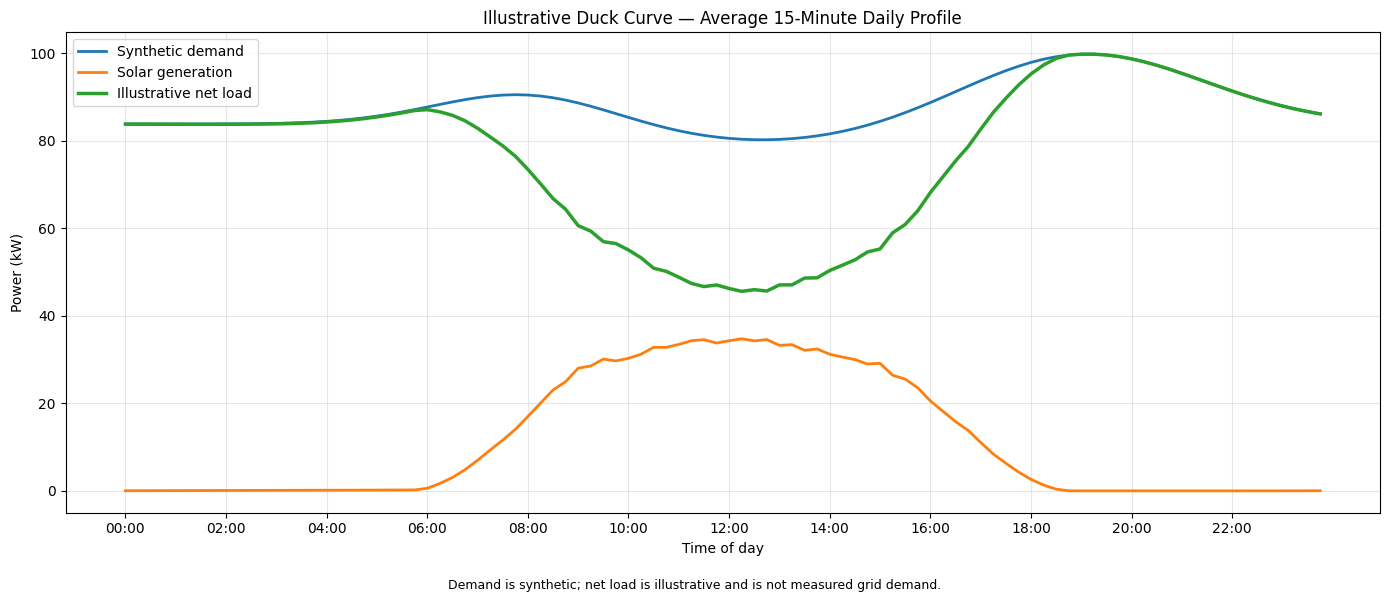

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plot_data = demand_data.dropna(subset=[
    "system_demand_synthetic_kw",
    "total_solar_generation_kw",
    "illustrative_net_load_kw"
]).copy()

if plot_data.empty:
    raise ValueError("No complete demand/solar rows are available to plot.")

# Convert timestamp to datetime so we can use the .dt accessor
plot_data["timestamp"] = pd.to_datetime(plot_data["timestamp"])
plot_data["time_of_day"] = plot_data["timestamp"].dt.strftime("%H:%M")

profile = (
    plot_data.groupby("time_of_day", sort=True)[[
        "system_demand_synthetic_kw",
        "total_solar_generation_kw",
        "illustrative_net_load_kw"
    ]]
    .mean()
)

# Plot against numeric positions so tick labels always align correctly.
x = np.arange(len(profile))
plt.figure(figsize=(14, 6))
plt.plot(x, profile["system_demand_synthetic_kw"].to_numpy(), label="Synthetic demand", linewidth=2)
plt.plot(x, profile["total_solar_generation_kw"].to_numpy(), label="Solar generation", linewidth=2)
plt.plot(x, profile["illustrative_net_load_kw"].to_numpy(), label="Illustrative net load", linewidth=2.5)

tick_positions = np.arange(0, len(profile), max(1, len(profile) // 12))
plt.xticks(tick_positions, profile.index[tick_positions], rotation=0)
plt.title("Illustrative Duck Curve — Average 15-Minute Daily Profile")
plt.xlabel("Time of day")
plt.ylabel("Power (kW)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.figtext(
    0.5, 0.01,
    "Demand is synthetic; net load is illustrative and is not measured grid demand.",
    ha="center", fontsize=9
)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

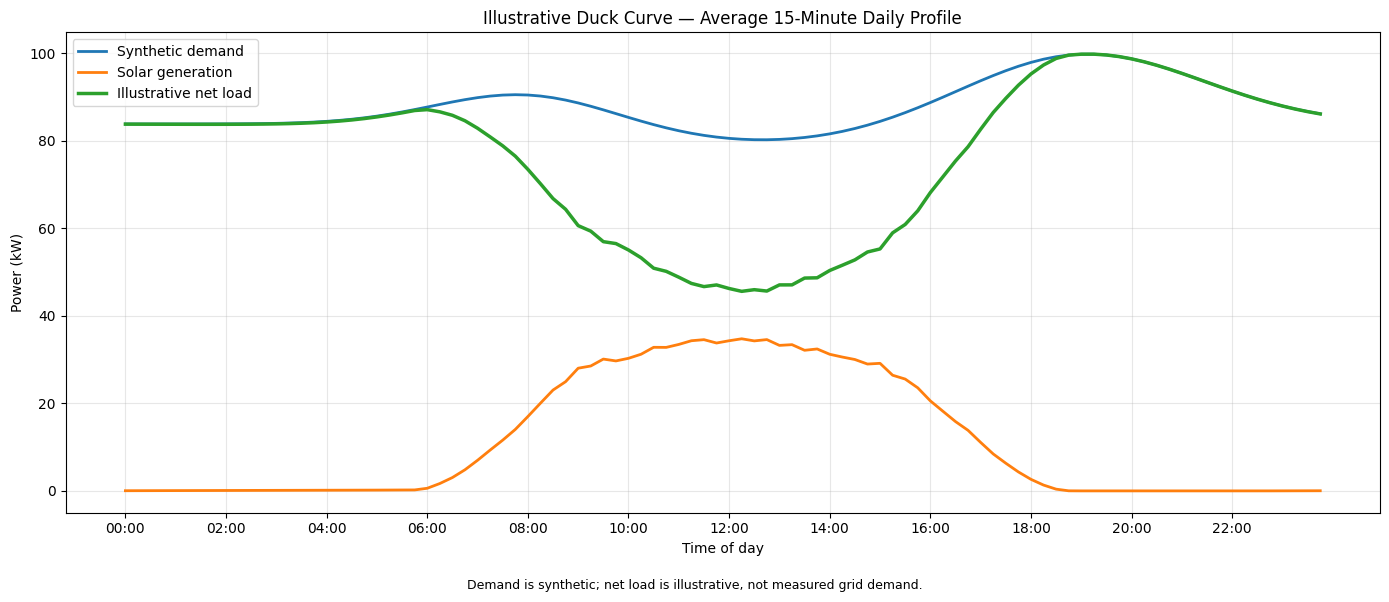

In [11]:
import numpy as np
import matplotlib.pyplot as plt

columns = [
    "system_demand_synthetic_kw",
    "total_solar_generation_kw",
    "illustrative_net_load_kw",
]

plot_data = demand_data.dropna(subset=columns).copy()
if plot_data.empty:
    raise ValueError("No complete demand/solar rows are available to plot.")

plot_data["time_of_day"] = plot_data["timestamp"].dt.strftime("%H:%M")
profile = plot_data.groupby("time_of_day", sort=True)[columns].mean()

x = np.arange(len(profile))
plt.figure(figsize=(14, 6))
plt.plot(x, profile["system_demand_synthetic_kw"].to_numpy(),
         label="Synthetic demand", linewidth=2)
plt.plot(x, profile["total_solar_generation_kw"].to_numpy(),
         label="Solar generation", linewidth=2)
plt.plot(x, profile["illustrative_net_load_kw"].to_numpy(),
         label="Illustrative net load", linewidth=2.5)

tick_positions = np.arange(0, len(profile), max(1, len(profile) // 12))
plt.xticks(tick_positions, profile.index[tick_positions], rotation=0)
plt.title("Illustrative Duck Curve — Average 15-Minute Daily Profile")
plt.xlabel("Time of day")
plt.ylabel("Power (kW)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.figtext(
    0.5, 0.01,
    "Demand is synthetic; net load is illustrative, not measured grid demand.",
    ha="center", fontsize=9
)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()
